In [1]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
from spinsimulation import *
%load_ext autoreload
%autoreload 2

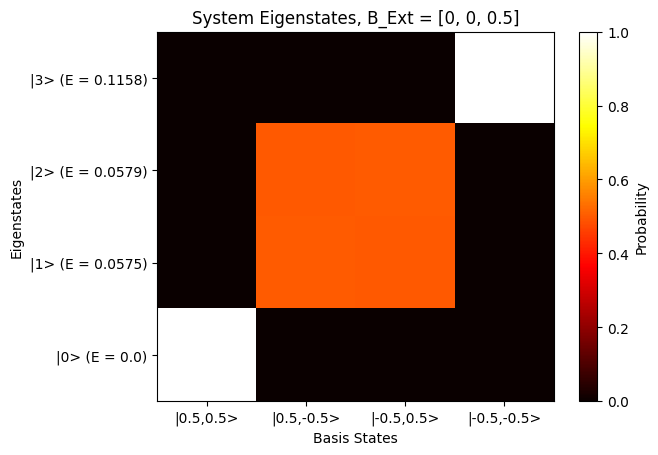

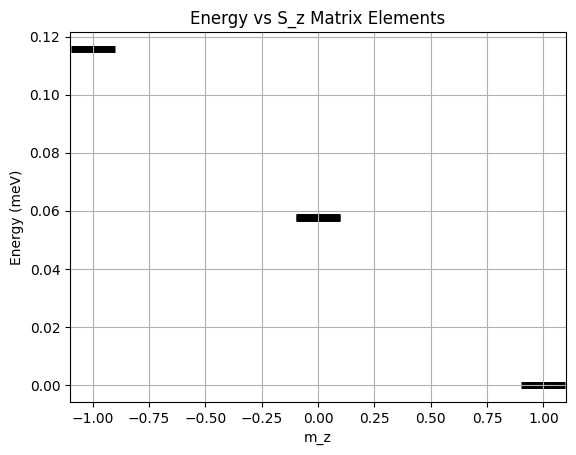

<module 'matplotlib.pyplot' from 'c:\\Users\\paulg\\.conda\\envs\\SIM\\Lib\\site-packages\\matplotlib\\pyplot.py'>

In [74]:
# Define the Spin System
spinsys=SpinSys([0.5, 0.5]) #  S=1/2

# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0.000] # Add a tipfield for driving
spinsys.T=1 
# Add Exchange interacion
spinsys.Jvector[0,:]=np.array([0.1*spinsys.GHztomeVConversion,0.1*spinsys.GHztomeVConversion,0.1*spinsys.GHztomeVConversion])
spinsys.DipoleBool=[False]
spinsys.AtomPositions[0] = [0,0,0]
spinsys.AtomPositions[1] = [1,2,0]

#vis.plotEigenMatrix(spinsys)
#vis.plotEnergyVsS(spinsys)
#vis.plotZeemanDiagramm(spinsys)

C:\Users\paulg\Desktop\Work\VS Code Projects\ternes_ldos\spinsimulation\calcBath.py:374: RuntimeWarning: invalid value encountered in scalar divide
  RateIntegrals[i, j] = abs(delta_E / (np.exp(delta_E / (spinsys.kB * spinsys.T)) - 1))


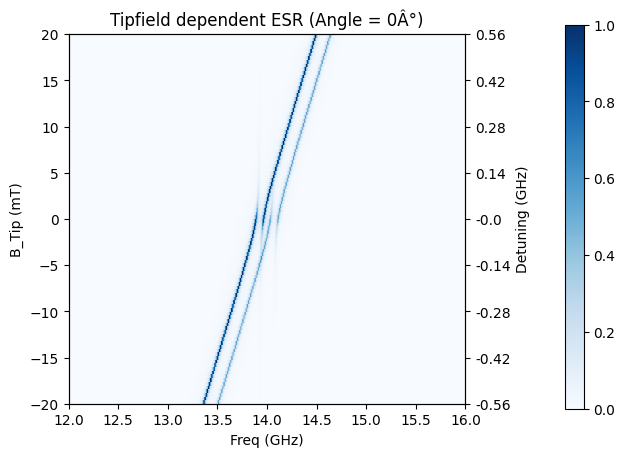

In [87]:
# Define the Spin System
spinsys=SpinSys([0.5, 0.5]) #  S=1/2

# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.BTip=[1e-6,0,0.000] # Add a tipfield for driving
spinsys.T=1 
# Add Exchange interacion
spinsys.Jvector[0,:]=np.array([0.1*spinsys.GHztomeVConversion,0.1*spinsys.GHztomeVConversion,0.1*spinsys.GHztomeVConversion])
spinsys.DipoleBool=[True]
spinsys.AtomPositions[0] = [0,0,0]
spinsys.AtomPositions[1] = [2,3,0]
#vis.plotESR_FreqSweep(spinsys, FreqRange = [12, 16], N = 1000, AllowPumping=False, norm= True)
#vis.plotESR_FreqSweep_ESRRate(spinsys, FreqRange = [12, 16], N = 1000, AllowPumping = True, T2 = 200, RabiRate = 1, norm = True)
vis.plotESR_Tipfieldsweep(spinsys, FreqRange= [12, 16], N_Freq = 1000, AllowPumping = True, norm = True, BTipRange=[-0.02,0.02])

In [ ]:
F=np.linspace(10, 20, 200)  # Frequency range for ESR
R=np.zeros(200)  # Initialize Rabi rates
for i in range(200):
    ESR.addESRrate(spinsys,T2=10, RabiRate=1, freq=F[i])  # Add ESR rates with different frequencies
    R[i]=spinsys.Rates[4][0][1]

print(spinsys.Rates[4][0][1])
#print('Populations:')
#print(spinsys.Populations)
plt.figure()
plt.plot(F, R)